# Lab 2.2: Building and Understanding Transformers with Multi-Head Attention

In this lab, you will:
- Understand the **Transformer architecture** and its motivation.
- Implement **Scaled Dot-Product Attention** and **Multi-Head Attention**.
- Add **Positional Encoding**.
- Build a **Transformer Encoder** step by step.
- Visualise the effect of different components.
- Train a Transformer as a **Language Model** on a larger corpus.
- Sample text with different temperatures to see probabilistic generation.

<table align="left">
  <td>
    <a href="https://colab.research.google.com/drive/1pPeI5_nkKDZuVJt0mO1QcKLjMGWA0Phv?usp=sharing" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>


In [1]:
!pip install -q datasets transformers torch

In [2]:
# Variables setup
d_k = 64
seq_len = 10
batch_size = 2
num_heads = 8 # This is for later Multi-Head Attention, but helps structure
d_model = 512


## 2. Scaled Dot-Product Attention

Implementing Scaled Dot-Product Attention

**Background:**

Scaled Dot-Product Attention is a core component of the Transformer architecture. It takes three inputs: Queries (Q), Keys (K), and Values (V). The attention mechanism calculates a weighted sum of the Values, where the weight of each Value is determined by the compatibility of the corresponding Key with the Query. This compatibility is typically calculated using a dot product. The scaling factor (dividing by the square root of the dimension of the keys, $d_k$) is crucial for preventing the dot products from becoming too large, especially with high dimensions, which can lead to vanishing gradients during training.

**Task:**
implement the `ScaledDotProductAttention` class in PyTorch. Your implementation should:

1.  Take Query (Q), Key (K), and Value (V) tensors as input. Assume these tensors have shapes `(batch_size, num_heads, seq_len, d_k)`.
2.  Calculate the raw attention scores by taking the dot product of Q and the transpose of K.
3.  Scale the raw scores by dividing by the square root of $d_k$.
4.  Optionally apply a mask to the scaled scores. Masked positions should have their scores set to a very small negative number (e.g., -1e9) to effectively zero out their contribution after the softmax.
5.  Apply the softmax function along the last dimension to get the attention weights.
6.  Calculate the output by taking the dot product of the attention weights and V.
7.  Return both the output tensor and the attention weights tensor.

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_k):
        super().__init__()
        self.d_k = d_k

    def forward(self, Q, K, V, mask=None):
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.d_k ** 0.5)
        if mask is not None:
          # apply masking
            scores = scores.masked_fill(mask == 0, -1e9)
        attn = F.softmax(scores, dim=-1)
        output = torch.matmul(attn, V)
        return output, attn


### => Test Case

In [4]:
# Test ScaledDotProductAttention
Q = torch.randn(batch_size, num_heads, seq_len, d_k)
K = torch.randn(batch_size, num_heads, seq_len, d_k)
V = torch.randn(batch_size, num_heads, seq_len, d_k)

# Create a dummy mask (e.g., causal mask)
mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0).expand(batch_size, num_heads, -1, -1)

attention = ScaledDotProductAttention(d_k=d_k)
output, attn_weights = attention(Q, K, V, mask=mask)

print("ScaledDotProductAttention Test:")
print("Input Q shape:", Q.shape)
print("Input K shape:", K.shape)
print("Input V shape:", V.shape)
print("Mask shape:", mask.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", attn_weights.shape)

# Expected output shape: (batch_size, num_heads, seq_len, d_k)
# Expected attention weights shape: (batch_size, num_heads, seq_len, seq_len)

ScaledDotProductAttention Test:
Input Q shape: torch.Size([2, 8, 10, 64])
Input K shape: torch.Size([2, 8, 10, 64])
Input V shape: torch.Size([2, 8, 10, 64])
Mask shape: torch.Size([2, 8, 10, 10])
Output shape: torch.Size([2, 8, 10, 64])
Attention weights shape: torch.Size([2, 8, 10, 10])


## 3. Multi-Head Attention



**Topic:** Implementing Multi-Head Attention

**Background:**

Multi-Head Attention is an extension of the attention mechanism that allows the model to jointly attend to information from different representation subspaces at different positions. It does this by performing the attention function in parallel with multiple "heads." Each head learns different linear projections of the Queries, Keys, and Values. The outputs from these attention heads are then concatenated and linearly transformed to produce the final output. This parallel processing with different learned projections helps the model capture a richer set of relationships in the data.

**Task:**

Implement the `MultiHeadAttention` class in PyTorch. Your implementation should:

1.  Take the input tensor `x` (representing the sequence) with shape `(batch_size, seq_len, d_model)`, and the number of attention heads `num_heads` as input during initialization. Assume the input `Q`, `K`, and `V` will be the same tensor `x` for self-attention.
2.  Implement linear layers (`W_q`, `W_k`, `W_v`, `W_o`) to project the input into Query, Key, and Value spaces, and for the final output projection.
3.  Split the projected Queries, Keys, and Values into `num_heads`.
4.  Apply the `ScaledDotProductAttention` (you can assume the previously implemented class is available) in parallel for each head.
5.  Concatenate the outputs from all attention heads.
6.  Apply the final linear transformation (`W_o`) to the concatenated output.
7.  Return the final output tensor and the attention weights from one of the heads (e.g., the first head) for potential visualization or analysis.

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_k = d_model // num_heads
        self.num_heads = num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attention = ScaledDotProductAttention(self.d_k)

    def forward(self, Q, K, V, mask=None):
        batch_size = Q.size(0)

        Q = self.W_q(Q)
        K = self.W_k(K)
        V = self.W_v(V)

        Q = Q.view(batch_size, -1, self.num_heads, self.d_k).transpose(1,2)
        K = K.view(batch_size, -1, self.num_heads, self.d_k).transpose(1,2)
        V = V.view(batch_size, -1, self.num_heads, self.d_k).transpose(1,2)

        out, attn = self.attention(Q, K, V, mask)

        out = out.transpose(1,2).contiguous().view(batch_size, -1, self.num_heads * self.d_k)
        return self.W_o(out), attn


### => Test Case

In [6]:
# Test MultiHeadAttention
# Input tensor with shape (batch_size, seq_len, d_model)
x = torch.randn(batch_size, seq_len, d_model)

multi_head_attention = MultiHeadAttention(d_model=d_model, num_heads=num_heads)
output, attn_weights = multi_head_attention(x, x, x)

print("Output shape:", output.shape)
print("Attention weights shape:", attn_weights.shape)

# Expected output shape: (batch_size, seq_len, d_model)
# Expected attention weights shape: (batch_size, num_heads, seq_len, seq_len)

Output shape: torch.Size([2, 10, 512])
Attention weights shape: torch.Size([2, 8, 10, 10])


## 4. Position-wise Feed Forward Network



**Topic:** Implementing Position-wise Feed Forward Network

**Background:**

The Position-wise Feed Forward Network (FFN) in a Transformer is a simple, fully connected feed-forward network that is applied independently to each position in the sequence. It consists of two linear transformations with a ReLU activation in between. While it processes each position separately, it uses the same weights across all positions. This allows it to introduce non-linearity and further transform the representations learned by the attention mechanism.

**Task:**

Implement the `PositionwiseFFN` class in PyTorch. Your implementation should:

1.  Take the input tensor `x` with shape `(batch_size, seq_len, d_model)` as input.
2.  Apply a linear transformation to project the input to a higher dimension (`d_ff`).
3.  Apply a ReLU activation function.
4.  Apply another linear transformation to project the output back to the original dimension (`d_model`).
5.  Return the output tensor with shape `(batch_size, seq_len, d_model)`.

=

In [7]:
class PositionwiseFFN(nn.Module):
    def __init__(self, d_model, d_ff=2048):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))


In [8]:
# Test PositionwiseFFN
d_ff = 2048

# Input tensor with shape (batch_size, seq_len, d_model)
x = torch.randn(batch_size, seq_len, d_model)

ffn = PositionwiseFFN(d_model=d_model, d_ff=d_ff)
output = ffn(x)

print("Output shape:", output.shape)

# Expected output shape: (batch_size, seq_len, d_model)

Output shape: torch.Size([2, 10, 512])


## 5. Positional Encoding

**Topic:** Implementing Positional Encoding

**Background:**

Transformers do not inherently process the order of tokens in a sequence. Positional Encoding is added to the input embeddings to inject information about the position of each token. This encoding is typically done using sinusoidal functions of different frequencies. This allows the model to distinguish between tokens at different positions and to understand the relative positions of tokens.

**Task:**

Implement the `PositionalEncoding` class in PyTorch. Your implementation should:

1.  Take the dimension of the model (`d_model`) and the maximum sequence length (`max_len`) as input during initialization.
2.  Create a `pe` tensor of shape `(max_len, d_model)` to store the positional encodings.
3.  Calculate the positional encodings using the sine and cosine functions based on the position and dimension. The formula for the encoding at position `pos` and dimension `i` is:
    $$
    PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
    $$
    $$
    PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
    $$
4.  Add the `pe` tensor to the input embeddings. Ensure the `pe` tensor is correctly sliced to match the sequence length of the input.
5.  Register the `pe` tensor as a buffer so it is not considered a model parameter.

In [9]:
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


In [10]:
# Test PositionalEncoding

max_len = 5000

# Input tensor with shape (batch_size, seq_len, d_model)
x = torch.randn(batch_size, seq_len, d_model)

pos_encoding = PositionalEncoding(d_model, max_len)
output = pos_encoding(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

# Expected output shape: (batch_size, seq_len, d_model)

Input shape: torch.Size([2, 10, 512])
Output shape: torch.Size([2, 10, 512])


## 6. Transformer Encoder Layer

In [11]:
import matplotlib.pyplot as plt


**Topic:** Implementing Transformer Encoder Layer

**Background:**

A Transformer Encoder Layer is a fundamental building block of the Transformer architecture. It typically consists of two main sub-layers: a Multi-Head Self-Attention mechanism and a Position-wise Feed Forward Network. Each of these sub-layers is followed by a residual connection and layer normalization. Dropout is often applied for regularization. The self-attention mechanism allows the layer to weigh the importance of different tokens in the input sequence when processing each token, while the feed-forward network further processes the attended information.

**Task:**

Implement the `TransformerEncoderLayer` class in PyTorch. Your implementation should:

1.  Take the dimension of the model (`d_model`), the number of attention heads (`num_heads`), and the dimension of the feed-forward network (`d_ff`) as input during initialization.
2.  Include instances of the `MultiHeadAttention` and `PositionwiseFFN` classes (you can assume they are available).
3.  Implement two Layer Normalization layers.
4.  Implement a Dropout layer.
5.  In the `forward` method, apply the Multi-Head Self-Attention to the input, followed by a residual connection, dropout, and layer normalization.
6.  Pass the output of the first sub-layer through the Position-wise Feed Forward Network, followed by another residual connection, dropout, and layer normalization.
7.  Return the output tensor of the encoder layer and the attention weights from the Multi-Head Attention layer for potential analysis.

In [12]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff=2048):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(0.1) # for regularisation

    def forward(self, x, mask=None):
        attn_out, attn_weights = self.mha(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_out))
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))
        return x, attn_weights


TransformerEncoderLayer Test:
Input shape: torch.Size([1, 20, 512])
Output shape: torch.Size([1, 20, 512])
Attention weights shape: torch.Size([1, 8, 20, 20])


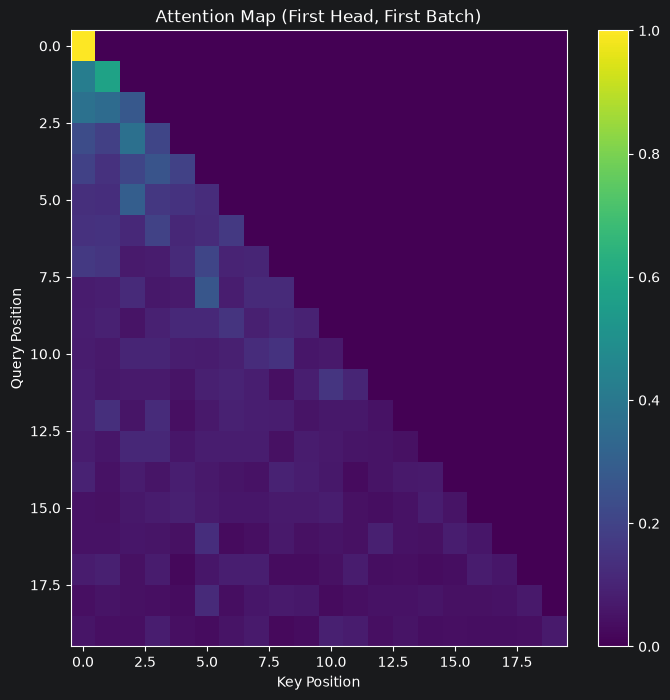

In [13]:
# Test TransformerEncoderLayer and visualize attention weights

seq_len = 20 # Use a slightly longer sequence for visualization
batch_size = 1 # Use a single batch for simpler visualization

# Input tensor with shape (batch_size, seq_len, d_model)
x = torch.randn(batch_size, seq_len, d_model)

# Create a dummy causal mask for visualization
mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0)

encoder_layer = TransformerEncoderLayer(d_model, num_heads, d_ff)
output, attn_weights = encoder_layer(x, mask=mask)

print("TransformerEncoderLayer Test:")
print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", attn_weights.shape)

# Visualize the attention weights of the first head in the batch
plt.figure(figsize=(8, 8))
plt.imshow(attn_weights[0, 0].detach().numpy(), cmap='viridis', aspect='auto')
plt.colorbar()
plt.title("Attention Map (First Head, First Batch)")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.show()

The visualized attention map shows a heatmap of the attention weights for the first attention head in the batch. The x-axis represents the key positions and the y-axis represents the query positions. The color intensity at each point (i, j) indicates the attention weight from the query at position i to the key at position j. Since a causal mask was used in this test, you should see that the attention weights are zero (or a very small negative number before softmax) for positions where the query is attending to a future key position (the upper triangle of the matrix should be masked). This means each token can only attend to itself and previous tokens in the sequence.

## 7. Transformer Language Model

**Topic:** Implementing Transformer Language Model

**Background:**

A Transformer Language Model is a type of Transformer network specifically designed for processing sequences of text and predicting the next token. It typically consists of an embedding layer, positional encoding, multiple Transformer Encoder layers, and a final linear layer to produce the output logits over the vocabulary. Language models are fundamental to many NLP tasks, including text generation, translation, and summarization.

**Task:**

Implement the `TransformerLM` class in PyTorch. Your implementation should:

1.  Take the vocabulary size (`vocab_size`), model dimension (`d_model`), number of attention heads (`num_heads`), number of encoder layers (`num_layers`), feed-forward dimension (`d_ff`), and maximum sequence length (`max_len`) as input during initialization.
2.  Include an `nn.Embedding` layer to convert input token IDs into dense vectors.
3.  Include the `PositionalEncoding` layer (you can assume it is available) to add positional information to the embeddings.
4.  Create a `nn.ModuleList` of `TransformerEncoderLayer` instances (you can assume it is available), stacking `num_layers` of them.
5.  Include a final linear layer (`fc_out`) to project the output of the last encoder layer to the vocabulary size.
6.  In the `forward` method, pass the input through the embedding layer, then the positional encoding, then sequentially through the stacked encoder layers.
7.  Apply the final linear layer to the output of the encoder stack.
8.  Return the final output logits (with shape `(batch_size, seq_len, vocab_size)`) and optionally the attention weights from each encoder layer for analysis.


In [14]:
class TransformerLM(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=2, d_ff=512, max_len=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_len)
        self.layers = nn.ModuleList(
            [TransformerEncoderLayer(d_model, num_heads, d_ff) for _ in range(num_layers)]
        )
        self.fc_out = nn.Linear(d_model, vocab_size)

    def forward(self, x, mask=None):
        x = self.embedding(x)
        x = self.pos_encoding(x)
        attn_weights_all = []
        for layer in self.layers:
            x, attn_weights = layer(x, mask)
            attn_weights_all.append(attn_weights)
        return self.fc_out(x), attn_weights_all


In [15]:
# Test TransformerLM
vocab_size = 1000 # Example vocabulary size
d_model = 128
num_heads = 4
num_layers = 2
d_ff = 512
max_len = 256
seq_len = 10 # Example sequence length
batch_size = 2 # Example batch size

# Input tensor with shape (batch_size, seq_len) representing token IDs
x = torch.randint(0, vocab_size, (batch_size, seq_len))

# Create a causal mask
mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0)
# Expand mask to match batch size and number of heads
mask = mask.expand(batch_size, num_heads, -1, -1)


model = TransformerLM(vocab_size, d_model, num_heads, num_layers, d_ff, max_len)
output, attn_weights_all = model(x, mask=mask)

print("TransformerLM Test:")
print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Number of attention weight tensors:", len(attn_weights_all))
print("Shape of attention weights from first layer:", attn_weights_all[0].shape)


# Expected input shape: (batch_size, seq_len)
# Expected output shape: (batch_size, seq_len, vocab_size)
# Expected shape of attention weights from each layer: (batch_size, num_heads, seq_len, seq_len)

TransformerLM Test:
Input shape: torch.Size([2, 10])
Output shape: torch.Size([2, 10, 1000])
Number of attention weight tensors: 2
Shape of attention weights from first layer: torch.Size([2, 4, 10, 10])


## 9. Training on WikiText-2

In [17]:

from datasets import load_dataset
from transformers import AutoTokenizer

dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
train_texts = "\n".join(dataset["train"]["text"])
val_texts = "\n".join(dataset["validation"]["text"])

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")

# Fix: set a padding token
tokenizer.pad_token = tokenizer.eos_token

# Now you can tokenize with padding
train_tokens = tokenizer(
    train_texts,
    return_tensors="pt",
    truncation=True,
    padding=True
)

print("Tokenized shape:", train_tokens["input_ids"].shape)

Tokenized shape: torch.Size([1, 1024])


## 10. Sampling Function

**Topic:** Implementing Text Sampling Function

**Background:**

After training a language model like the TransformerLM, we need a way to generate new text based on a given prompt. This is typically done by sampling the next token from the probability distribution predicted by the model at each step, and then feeding the generated token back as input to predict the subsequent token. The `temperature` parameter is often used during sampling to control the randomness of the generated text. A higher temperature leads to more diverse but potentially less coherent text, while a lower temperature makes the output more deterministic and focused.

**Task:**

Implement a `generate_text` function in PyTorch that takes a trained `TransformerLM` model, a tokenizer, a starting prompt string, the maximum number of new tokens to generate, and a temperature as input. Your function should:

1.  Set the model to evaluation mode.
2.  Tokenize the input prompt.
3.  Iteratively generate new tokens:
    *   Pass the current sequence of tokens through the model to get the output logits.
    *   Apply the temperature to the logits (divide by temperature).
    *   Apply a softmax function to get the probability distribution over the vocabulary for the next token.
    *   Sample the next token from this probability distribution using `torch.multinomial`.
    *   Append the sampled token to the sequence of tokens.
4.  Decode the final sequence of tokens back into a string using the tokenizer.
5.  Return the generated text.

In [18]:
import torch.nn.functional as F

def generate_text(model, tokenizer, prompt, max_new_tokens=50, temperature=1.0):
    model.eval()
    tokens = tokenizer(prompt, return_tensors="pt")["input_ids"]
    for _ in range(max_new_tokens):
        with torch.no_grad():
            logits, _ = model(tokens)
            logits = logits[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            tokens = torch.cat([tokens, next_token], dim=1)
    return tokenizer.decode(tokens[0])


In [19]:
# Define vocab size from tokenizer
vocab_size = len(tokenizer)

# Instantiate our custom Transformer language model
model = TransformerLM(vocab_size=vocab_size, d_model=128, num_heads=4, num_layers=2)

# 11- Training Loop

In [20]:
import torch.optim as optim

# Define optimizer and loss function
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.pad_token_id)

# Prepare data for training (simple example, will need more sophisticated data loading for real training)
# For this example, we'll just use a small subset of the tokenized training data
train_input_ids = train_tokens["input_ids"][:, :max_len] # Use max_len for sequence length
train_attention_mask = train_tokens["attention_mask"][:, :max_len]

# Create causal mask for training
seq_len = train_input_ids.size(1)
causal_mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0)
# Expand mask to match batch size and number of heads (assuming batch size 1 for this simple example)
# In a real scenario, you'd handle batches properly
batch_size = train_input_ids.size(0)
num_heads = model.layers[0].mha.num_heads # Get num_heads from the first MHA layer
causal_mask = causal_mask.expand(batch_size, num_heads, -1, -1).to(train_input_ids.device)


# Training loop (simplified for demonstration)
epochs = 50
for epoch in range(epochs):
    model.train()
    total_loss = 0
    # In a real scenario, you would iterate through batches of data
    # For this example, we'll just use the whole small dataset as one batch
    inputs = train_input_ids
    targets = train_input_ids.clone() # Target is the next token

    # Shift targets for language modeling: predict next token
    targets[:, :-1] = train_input_ids[:, 1:]
    targets[:, -1] = tokenizer.pad_token_id # Use pad_token_id for the last token target

    optimizer.zero_grad()
    outputs, _ = model(inputs, mask=causal_mask)

    # Reshape for CrossEntropyLoss
    outputs = outputs.view(-1, vocab_size)
    targets = targets.view(-1)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss}")

# Note: This is a very basic training loop for demonstration.
# A real training setup would involve data loaders, batching,
# more epochs, and potentially early stopping and logging.

Epoch 1, Loss: 10.977715492248535
Epoch 2, Loss: 10.550395965576172
Epoch 3, Loss: 10.18762493133545
Epoch 4, Loss: 9.872209548950195
Epoch 5, Loss: 9.608677864074707
Epoch 6, Loss: 9.3504056930542
Epoch 7, Loss: 9.095046043395996
Epoch 8, Loss: 8.8229398727417
Epoch 9, Loss: 8.549332618713379
Epoch 10, Loss: 8.264491081237793
Epoch 11, Loss: 7.979127883911133
Epoch 12, Loss: 7.701554298400879
Epoch 13, Loss: 7.429906368255615
Epoch 14, Loss: 7.1760125160217285
Epoch 15, Loss: 6.899074554443359
Epoch 16, Loss: 6.635295391082764
Epoch 17, Loss: 6.377743721008301
Epoch 18, Loss: 6.0976643562316895
Epoch 19, Loss: 5.85442590713501
Epoch 20, Loss: 5.5835113525390625
Epoch 21, Loss: 5.336874485015869
Epoch 22, Loss: 5.079893112182617
Epoch 23, Loss: 4.8243727684021
Epoch 24, Loss: 4.600675106048584
Epoch 25, Loss: 4.358225345611572
Epoch 26, Loss: 4.129444599151611
Epoch 27, Loss: 3.9173429012298584
Epoch 28, Loss: 3.6898186206817627
Epoch 29, Loss: 3.469336748123169
Epoch 30, Loss: 3.26514

## 12. Visualising Sampling Effect

In [21]:
for temp in [0.5, 1.0, 1.5]:
    print(f"\n--- Temperature {temp} ---")
    print(generate_text(model, tokenizer, "Generative AI is", max_new_tokens=30, temperature=temp))


--- Temperature 0.5 ---
Generative AI is the third game , commonly referred to as Valkyria Chronicles III outside Japan , commonly referred to as Valkyria Chronicles II director Takes by Sega and

--- Temperature 1.0 ---
Generative AI is unit Sega ,oward , the Valkyriainga Valkyvance Invest of the it is Battlefield .ilatedeless done during the alsoinitely Hide Blocks

--- Temperature 1.5 ---
Generative AI isTalk IPAirds CE nickel Oculus Wells}} RX Cal connector same Plymouth desktopcess124runtimeIowa dripping populated Croatiair neurologventalthough paragraphUnlike ammonianin softly


## Wrap-Up
- Built Transformer components step by step.
- Visualised positional encodings and attention maps.
- Trained on WikiText-2 with a tokenizer.
- Sampled text with different temperatures to observe diversity.
